# Review 3 — Model 2: CNN–BiLSTM

**Deep Learning-Based Virtual Race Engineer for Real-Time Formula 1 Strategy Optimization**

Dhruv Deepak (23BCE9187) · Akhil V (23BCE8051) · Mohan Simha Varma Dantuluri (23BCE9229) · Surya Prathap Mamillapalli (23BCE7783)

---

## The second of three architectures

Model 2 answers the **same question** as Model 1 — given the last 10 laps of telemetry for a
driver, will that driver pit within the next 3 laps? — on the same data, the same splits and the
same training protocol. Only the architecture changes, which is what makes the Review 3
comparison meaningful.

### The idea: a division of labour Model 1 does not have

Two `Conv1D` layers slide over the **lap axis** and pick up short local motifs — a three-lap burst
of degradation, a lap-time spike from traffic or a safety car, a sudden drop after a tyre change.
They hand those cleaner, higher-level features to a bidirectional LSTM, which is then left to
model only how the motifs evolve across the window.

A bare LSTM has to discover the motifs *and* their evolution in the same set of weights. This
follows the CNN–BiLSTM benchmarked by Sasikumar et al. (2025).

### One deliberate deviation from the textbook

Standard CNN-LSTM stacks put a pooling layer between the convolutional and recurrent halves.
**This model has none.** The sequence is only `SEQ_LEN = 10` steps long, so even a stride-2 pool
would throw away half the temporal resolution the recurrent layer exists to read.

## 1. Setup

All pipeline logic lives in `src/` as importable modules. The notebook presents it; it does not redefine it.

In [1]:
import sys, json, time, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import keras
from IPython.display import Image, display

from src import config
from src.evaluation import metrics as M, plots

config.ensure_dirs()
config.set_seed()
plots.apply_style()
print("keras", keras.__version__, "| project", config.PROJECT_ROOT)

keras 3.12.0 | project C:\E\Project\Deep Learning


## 2. The dataset — identical to Model 1

`src/features/build_dataset.py` already produced these tensors. Model 2 loads the *same file*,
so any difference in score comes from the architecture and nothing else.

In [2]:
from src.models import architectures, train as train_mod

data, meta = train_mod.load_dataset()
X_train, y_train = data["X_train"], data["y_train"]
X_val,   y_val   = data["X_val"],   data["y_val"]
X_test,  y_test  = data["X_test"],  data["y_test"]

pd.DataFrame({
    "split":     ["train", "validation", "test"],
    "seasons":   [config.TRAIN_SEASONS, config.VAL_SEASONS, config.TEST_SEASONS],
    "samples":   [len(X_train), len(X_val), len(X_test)],
    "positive %":[round(100*y_train.mean(),2), round(100*y_val.mean(),2), round(100*y_test.mean(),2)],
})

,split,seasons,samples,positive %
0,train,"[2021, 2022]",38890,9.15
1,validation,[2023],20152,9.55
2,test,[2024],22228,8.52


## 3. The architecture

`Conv1D(16) → BatchNorm → Conv1D(16) → BatchNorm → Dropout → Bi-LSTM(16) → Dense → sigmoid`

Batch normalisation sits after each convolution because the 55 inputs are standardised globally
but the convolution outputs are not; normalising them keeps the recurrent layer's inputs stable
from the first epoch, which matters when training stops after a handful of epochs.

### Where the widths came from

A six-configuration sweep, matching the one Model 1 received, selected on validation PR-AUC
alone. **The smallest variant won** — 16 filters with a 16-unit LSTM, 8,881 parameters:

| Config | Params | Val PR-AUC | Test PR-AUC |
|---|---|---|---|
| 64f k3, LSTM 32 | 50,433 | 0.3172 | 0.294 |
| 32f k3, LSTM 32 | 27,425 | 0.3005 | 0.281 |
| 64f **k5**, LSTM 32 | 65,665 | 0.2857 | 0.259 |
| **16f k3, LSTM 16** | **8,881** | **0.3316** | **0.301** |
| 32f k3, LSTM 64 | 62,497 | 0.3036 | 0.300 |
| 32f k3, dropout 0.5, L2 1e-3 | 27,425 | 0.3070 | 0.285 |

Widening the kernel hurt most: at a 10-lap window a kernel of 5 spans half the sequence, so the
convolution stops detecting *local* motifs and starts duplicating what the recurrent layer
already does.

Every configuration landed between 0.259 and 0.301 test PR-AUC, all below Model 1 — so Model 2
trailing is a property of the architecture on this data, not of how hard it was tuned.

In [3]:
pos_weight = train_mod.positive_weight(y_train)
model = architectures.build("cnn_bilstm", input_shape=(X_train.shape[1], X_train.shape[2]),
                            pos_weight=pos_weight)
print(f"positive class weight = {pos_weight:.2f}\n")
model.summary()

positive class weight = 9.93



Model: "cnn_bilstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv1D)                 │ (None, 10, 16)         │         2,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batchnorm_1                     │ (None, 10, 16)         │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv1D)                 │ (None, 10, 16)         │           784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batchnorm_2                     │ (None, 10, 16)         │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 10, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bilstm (Bidirectional)          │ (None, 32)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pit_probability (Dense)         │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,881 (34.69 KB)

 Trainable params: 8,817 (34.44 KB)

 Non-trainable params: 64 (256.00 B)

## 4. Training

> **`RETRAIN = False` by default.** The notebook loads the weights and
> predictions saved by the committed training runs, so the numbers shown here are
> exactly the ones in the report and the deck. Set `RETRAIN = True` to train a
> fresh copy live (about a minute on CPU) — it builds and fits the model inside
> the notebook and does **not** overwrite the published artefacts.

In [4]:
RETRAIN = False
NAME = "cnn_bilstm"

stored = json.load(open(config.METRICS_DIR / f"{NAME}_metrics.json"))

if RETRAIN:
    t0 = time.perf_counter()
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                        epochs=config.EPOCHS, batch_size=config.BATCH_SIZE,
                        callbacks=[keras.callbacks.EarlyStopping(
                            monitor="val_pr_auc", mode="max",
                            patience=config.EARLY_STOPPING_PATIENCE,
                            restore_best_weights=True)],
                        verbose=2)
    hist = history.history
    val_prob  = model.predict(X_val,  batch_size=512, verbose=0).ravel()
    test_prob = model.predict(X_test, batch_size=512, verbose=0).ravel()
    print(f"\ntrained {len(hist['loss'])} epochs in {time.perf_counter()-t0:.1f}s")
else:
    hist = stored["history"]
    probs = np.load(config.METRICS_DIR / f"{NAME}_probs.npz")
    val_prob, test_prob = probs["val"], probs["test"]
    print(f"loaded the committed run: {stored['epochs_run']} epochs, "
          f"{stored['train_time_s']}s, {stored['n_parameters']:,} parameters")

loaded the committed run: 14 epochs, 49.2s, 8,881 parameters


## 5. Accuracy and loss graphs

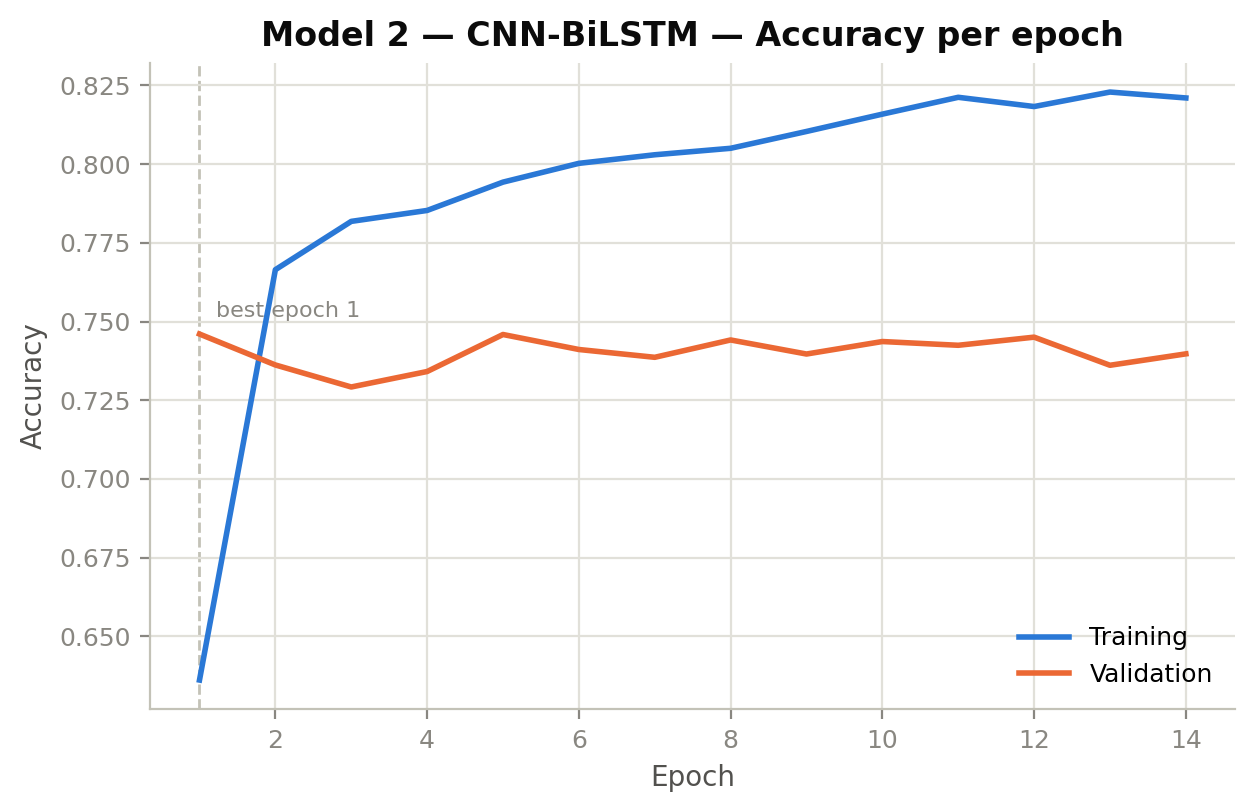

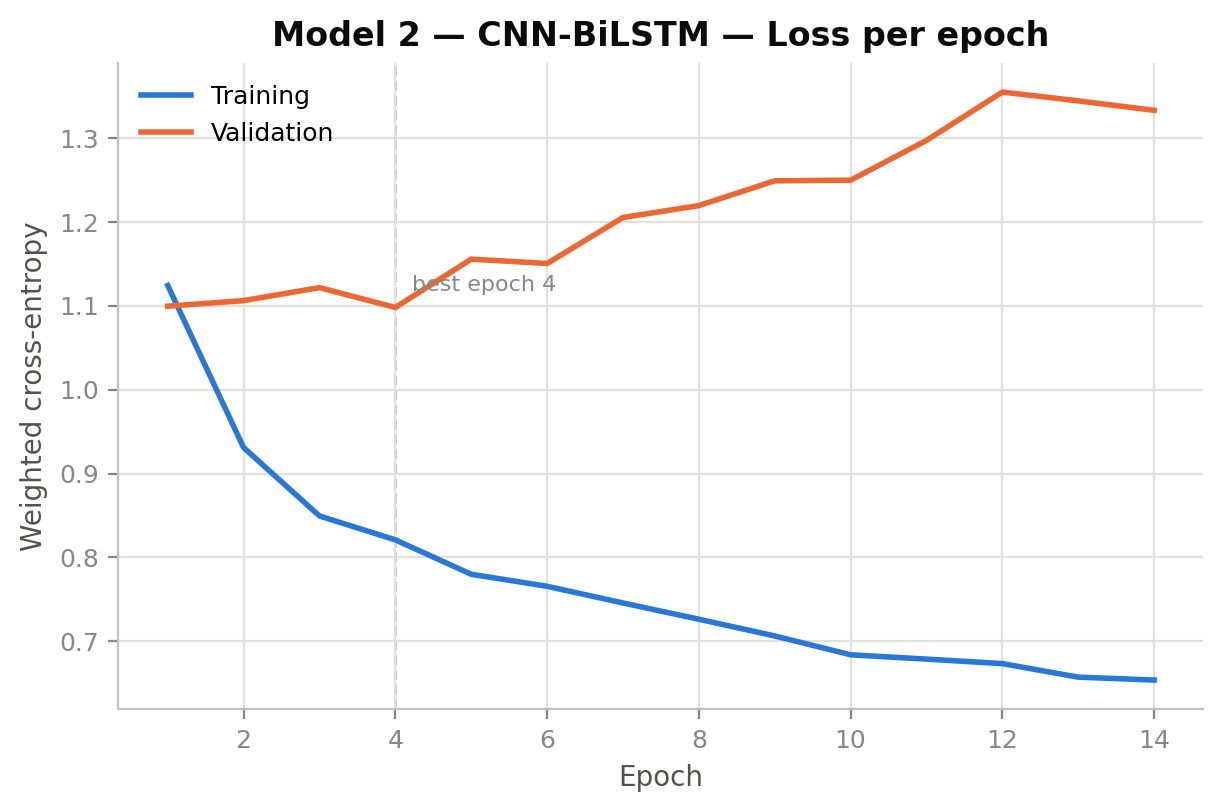

In [5]:
acc_png  = plots.plot_accuracy(hist, NAME, "Model 2 — CNN-BiLSTM")
loss_png = plots.plot_loss(hist,  NAME, "Model 2 — CNN-BiLSTM")
display(Image(acc_png)); display(Image(loss_png))

Validation loss turns upward within the first few epochs while training loss keeps falling —
the same overfitting signature Model 1 shows, and for the same reason: 38,890 training windows
come from only 815 driver-races, and consecutive windows share 9 of their 10 laps.

## 6. Threshold, results and confusion matrix

The threshold is tuned on **validation** and then applied unchanged to test. Tuning it on test
would be using the test set to make a modelling decision.

In [6]:
threshold, val_f1 = M.tune_threshold(y_val, val_prob)
print(f"tuned threshold: {threshold:.3f} (validation F1 {val_f1:.4f})")

baseline     = M.majority_baseline(y_test)
test_default = M.compute(y_test, test_prob, 0.5)
test_tuned   = M.compute(y_test, test_prob, threshold)

pd.DataFrame([
    {"model": "Never-pit baseline", **{k: baseline[k] for k in ("accuracy","balanced_accuracy","precision","recall","f1","roc_auc","pr_auc")}},
    {"model": "CNN-BiLSTM @ 0.50",  **{k: test_default[k] for k in ("accuracy","balanced_accuracy","precision","recall","f1","roc_auc","pr_auc")}},
    {"model": "CNN-BiLSTM @ tuned", **{k: test_tuned[k] for k in ("accuracy","balanced_accuracy","precision","recall","f1","roc_auc","pr_auc")}},
]).set_index("model").round(4)

tuned threshold: 0.796 (validation F1 0.4051)


,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,,
Never-pit baseline,0.9148,0.5000,0.0000,0.0000,0.0000,0.5000,0.0852
CNN-BiLSTM @ 0.50,0.7118,0.7077,0.1855,0.7027,0.2935,0.7717,0.3055
CNN-BiLSTM @ tuned,0.8404,0.6760,0.2613,0.4778,0.3378,0.7717,0.3055


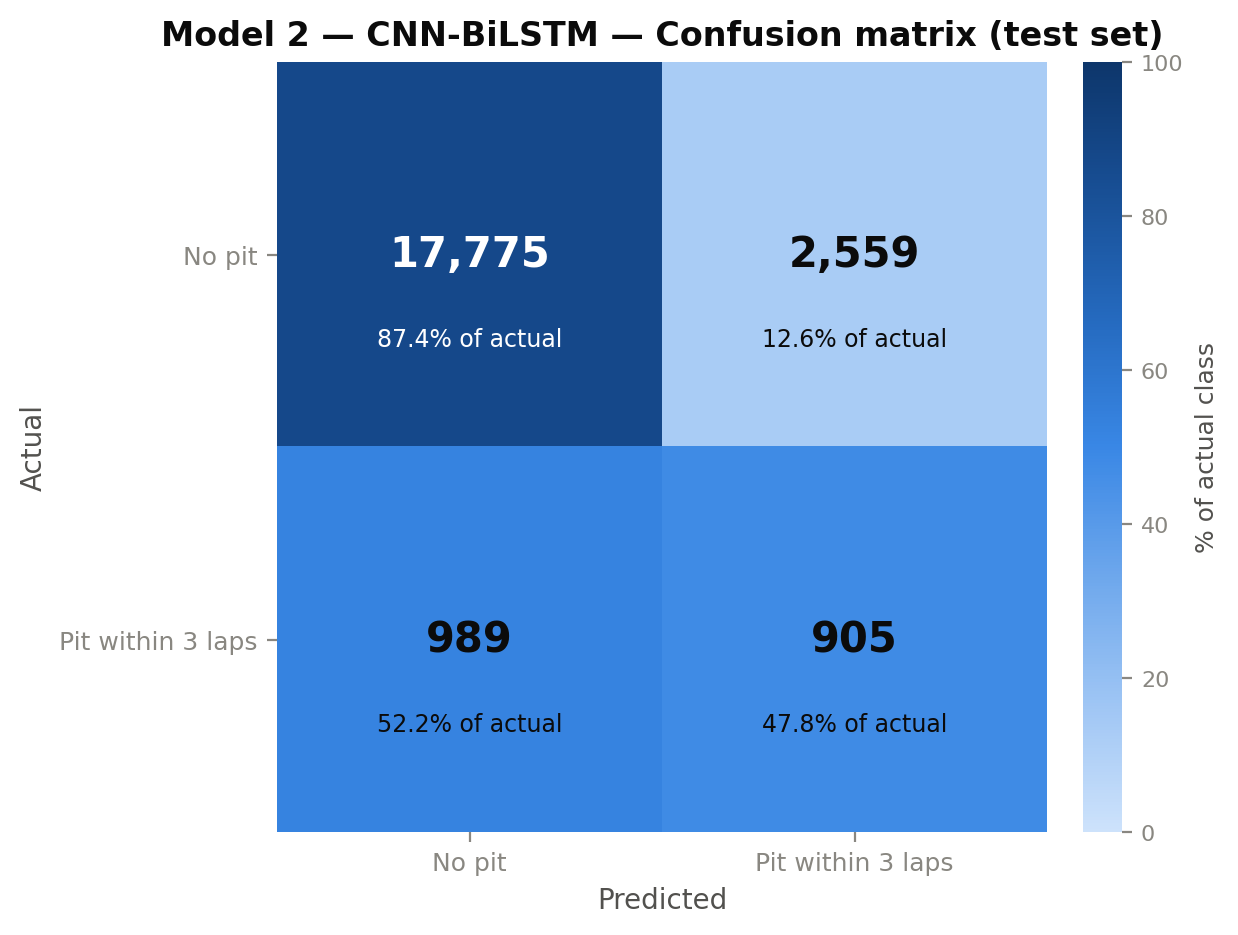

Pit stops anticipated : 905 of 1,894 (47.8%)
False alarms          : 2,559


In [7]:
cm_png = plots.plot_confusion_matrix(np.array(test_tuned["confusion_matrix"]), NAME,
                                     "Model 2 — CNN-BiLSTM")
display(Image(cm_png))
print(f"Pit stops anticipated : {test_tuned['true_positives']:,} of "
      f"{test_tuned['true_positives']+test_tuned['false_negatives']:,} "
      f"({100*test_tuned['recall']:.1f}%)")
print(f"False alarms          : {test_tuned['false_positives']:,}")

## 7. Where Model 2 stands

It gives up a little accuracy to Model 1 but is **12× smaller** and slightly faster per lap. Which
matters depends on whether the deployment is constrained by accuracy or by cost — the full
comparison is in notebook `04`.

Next: **Model 3**, the project's proposed contribution, in notebook `03`.